## **Prediksi Hujan di Jakarta Berdasarkan Integrasi Data Cuaca, Kualitas Udara, dan Kondisi Laut Menggunakan Algoritma Random Forest dan Gradient Boosting**

**Nama** : Gilang Syah Fitrah Ramadhan  
**NIM** : E1E124037

### Latar Belakang

Kondisi hujan di wilayah Jakarta dipengaruhi oleh berbagai faktor atmosfer dan lingkungan. Data cuaca seperti suhu, kelembapan, curah hujan, kecepatan angin, tekanan udara, dan tutupan awan dapat memberikan gambaran kondisi atmosfer.

Selain itu, kualitas udara dan kondisi laut juga dapat memberikan informasi tambahan yang relevan untuk memahami perubahan kondisi lingkungan. Oleh karena itu, proyek ini mengintegrasikan tiga sumber data, yaitu data cuaca, kualitas udara, dan kondisi laut untuk menganalisis pola lingkungan serta membangun model klasifikasi hujan dan tidak hujan di Jakarta.

Data yang digunakan memiliki resolusi per jam dan berasal dari tiga dataset yang telah diproses melalui Apache Airflow kemudian disimpan ke database MySQL.

Dataset yang digunakan terdiri dari:

- `weather_data` sebagai dataset utama
- `air_quality_data` sebagai dataset pendukung pertama
- `marine_data` sebagai dataset pendukung kedua

Ketiga dataset memiliki kolom waktu `time` yang nantinya digunakan sebagai **key** dalam proses integrasi data.

### Tujuan Proyek

Proyek ini bertujuan untuk:

- Menganalisis karakteristik kondisi cuaca di Jakarta.
- Menganalisis hubungan kondisi cuaca dengan kualitas udara.
- Menganalisis hubungan kondisi laut dengan kondisi cuaca.
- Mengintegrasikan tiga dataset berdasarkan waktu.
- Membangun model klasifikasi kondisi **hujan** dan **tidak hujan**.
- Membandingkan performa algoritma **Random Forest** dan **Gradient Boosting**.

### Pertanyaan Bisnis

1. Bagaimana karakteristik umum kondisi cuaca di Jakarta selama periode pengamatan berdasarkan suhu, kelembapan, curah hujan, kecepatan angin, tekanan udara, dan tutupan awan?

2. Bagaimana hubungan antara kondisi cuaca dengan kualitas udara di Jakarta, khususnya terhadap konsentrasi **PM2.5, PM10, nitrogen dioksida (NO₂), dan ozon (O₃)**?

3. Bagaimana hubungan suhu permukaan laut dengan kondisi cuaca di Jakarta, terutama terhadap suhu udara, kelembapan, tutupan awan, dan curah hujan?

4. Seberapa baik algoritma **Random Forest** dan **Gradient Boosting** dalam memprediksi kondisi **hujan** atau **tidak hujan** berdasarkan integrasi data cuaca, kualitas udara, dan kondisi laut, serta algoritma mana yang memberikan performa terbaik?

In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Database connection
from sqlalchemy import create_engine

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Utility
import warnings
warnings.filterwarnings("ignore")

print("Library berhasil di-import.")

Library berhasil di-import.


## 4. Data Wrangling

### A. Gathering Data

Pada tahap ini, tiga dataset dimuat langsung dari database MySQL `weather_ml` yang merupakan hasil proses ETL menggunakan Apache Airflow. Dataset yang digunakan terdiri dari `weather_data` sebagai dataset utama, `air_quality_data` sebagai dataset pendukung pertama, dan `marine_data` sebagai dataset pendukung kedua.

In [4]:
# Membuat koneksi ke database MySQL
engine = create_engine(
    "mysql+pymysql://root:@127.0.0.1:3306/weather_ml"
)

# Load dataset utama
df_weather = pd.read_sql(
    "SELECT * FROM weather_data",
    con=engine
)

# Load dataset pendukung 1
df_air = pd.read_sql(
    "SELECT * FROM air_quality_data",
    con=engine
)

# Load dataset pendukung 2
df_marine = pd.read_sql(
    "SELECT * FROM marine_data",
    con=engine
)

print("Ketiga dataset berhasil dimuat dari database.")

Ketiga dataset berhasil dimuat dari database.


#### 1. Dataset Utama — Weather Data

In [5]:
print("Jumlah data weather:", df_weather.shape)
df_weather.head()

Jumlah data weather: (2208, 8)


,id,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,surface_pressure,cloud_cover
0,1,2026-06-29 00:00:00,26.8,84.0,0.0,2.7,1008.8,7.0
1,2,2026-06-29 01:00:00,27.1,84.0,0.0,2.2,1008.9,16.0
2,3,2026-06-29 02:00:00,26.8,87.0,0.0,2.1,1008.3,9.0
3,4,2026-06-29 03:00:00,26.8,85.0,0.0,2.5,1008.0,2.0
4,5,2026-06-29 04:00:00,26.5,86.0,0.0,3.3,1008.2,2.0


#### 2. Dataset Pendukung 1 — Air Quality Data

In [6]:
print("Jumlah data air quality:", df_air.shape)

df_air.head()

Jumlah data air quality: (2208, 6)


,id,time,pm2_5,pm10,nitrogen_dioxide,ozone
0,1,2026-06-29 00:00:00,135.0,136.4,87.9,2.0
1,2,2026-06-29 01:00:00,126.7,128.1,83.8,2.0
2,3,2026-06-29 02:00:00,122.9,124.3,80.0,1.0
3,4,2026-06-29 03:00:00,119.7,120.6,75.9,0.0
4,5,2026-06-29 04:00:00,114.1,115.0,71.8,0.0


#### 3. Dataset Pendukung 2 — Marine Data

In [7]:
print("Jumlah data marine:", df_marine.shape)

df_marine.head()

Jumlah data marine: (2208, 5)


,id,time,wave_height,wave_period,sea_surface_temperature
0,1,2026-06-29 00:00:00,None,None,30.3
1,2,2026-06-29 01:00:00,None,None,30.3
2,3,2026-06-29 02:00:00,None,None,30.3
3,4,2026-06-29 03:00:00,None,None,30.2
4,5,2026-06-29 04:00:00,None,None,30.2


### B. Assessing Data

Assessing dilakukan secara terpisah pada ketiga dataset untuk mengidentifikasi kondisi data sebelum proses cleaning. Pemeriksaan meliputi struktur data, statistik deskriptif, missing value, duplicate, tipe data, dan nilai yang tidak sesuai.

##1. Weather

In [8]:
print("=== INFO WEATHER ===")
df_weather.info()

print("\n=== STATISTIK DESKRIPTIF WEATHER ===")
display(df_weather.describe(include="all"))

print("\n=== MISSING VALUE WEATHER ===")
display(df_weather.isnull().sum())

print("\nJumlah duplicate:", df_weather.duplicated().sum())

print("\nTipe data:")
display(df_weather.dtypes)

=== INFO WEATHER ===
<class 'pandas.DataFrame'>
RangeIndex: 2208 entries, 0 to 2207
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id                    2208 non-null   int64         
 1   time                  2208 non-null   datetime64[us]
 2   temperature_2m        2208 non-null   float64       
 3   relative_humidity_2m  2208 non-null   float64       
 4   precipitation         2208 non-null   float64       
 5   wind_speed_10m        2208 non-null   float64       
 6   surface_pressure      2208 non-null   float64       
 7   cloud_cover           2208 non-null   float64       
dtypes: datetime64[us](1), float64(6), int64(1)
memory usage: 138.1 KB

=== STATISTIK DESKRIPTIF WEATHER ===


,id,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,surface_pressure,cloud_cover
count,2208.000000,2208,2208.000000,2208.000000,2208.000000,2208.000000,2208.000000,2208.000000
mean,1104.500000,2026-08-13 23:30:00,29.346105,62.605525,0.058197,6.328759,1010.261911,41.180254
min,1.000000,2026-06-29 00:00:00,22.700000,20.000000,0.000000,0.000000,1005.300000,0.000000
25%,552.750000,2026-07-21 23:45:00,26.900000,51.000000,0.000000,3.800000,1009.200000,9.000000
50%,1104.500000,2026-08-13 23:30:00,28.800000,64.000000,0.000000,5.600000,1010.400000,33.000000
75%,1656.250000,2026-09-05 23:15:00,31.700000,74.000000,0.000000,8.500000,1011.500000,75.000000
max,2208.000000,2026-09-28 23:00:00,36.700000,100.000000,8.900000,18.200000,1014.300000,100.000000
std,637.539018,NaN,2.829722,14.874820,0.335899,3.371268,1.654857,34.638533



=== MISSING VALUE WEATHER ===


id                      0
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
surface_pressure        0
cloud_cover             0
dtype: int64


Jumlah duplicate: 0

Tipe data:


id                               int64
time                    datetime64[us]
temperature_2m                 float64
relative_humidity_2m           float64
precipitation                  float64
wind_speed_10m                 float64
surface_pressure               float64
cloud_cover                    float64
dtype: object

In [9]:
print("Kelembapan di luar 0-100:",
      ((df_weather["relative_humidity_2m"] < 0) |
       (df_weather["relative_humidity_2m"] > 100)).sum())

print("Cloud cover di luar 0-100:",
      ((df_weather["cloud_cover"] < 0) |
       (df_weather["cloud_cover"] > 100)).sum())

print("Precipitation negatif:",
      (df_weather["precipitation"] < 0).sum())

print("Wind speed negatif:",
      (df_weather["wind_speed_10m"] < 0).sum())

Kelembapan di luar 0-100: 0
Cloud cover di luar 0-100: 0
Precipitation negatif: 0
Wind speed negatif: 0


##2. Air Quality

In [10]:
print("=== INFO AIR QUALITY ===")
df_air.info()

print("\n=== STATISTIK DESKRIPTIF AIR QUALITY ===")
display(df_air.describe(include="all"))

print("\n=== MISSING VALUE AIR QUALITY ===")
display(df_air.isnull().sum())

print("\nJumlah duplicate:", df_air.duplicated().sum())

print("\nTipe data:")
display(df_air.dtypes)

=== INFO AIR QUALITY ===
<class 'pandas.DataFrame'>
RangeIndex: 2208 entries, 0 to 2207
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                2208 non-null   int64         
 1   time              2208 non-null   datetime64[us]
 2   pm2_5             2208 non-null   float64       
 3   pm10              2208 non-null   float64       
 4   nitrogen_dioxide  2208 non-null   float64       
 5   ozone             2208 non-null   float64       
dtypes: datetime64[us](1), float64(4), int64(1)
memory usage: 103.6 KB

=== STATISTIK DESKRIPTIF AIR QUALITY ===


,id,time,pm2_5,pm10,nitrogen_dioxide,ozone
count,2208.000000,2208,2208.000000,2208.000000,2208.000000,2208.000000
mean,1104.500000,2026-08-13 23:30:00,84.696558,86.944384,58.435553,87.560688
min,1.000000,2026-06-29 00:00:00,21.700000,22.400000,5.500000,0.000000
25%,552.750000,2026-07-21 23:45:00,53.775000,55.750000,29.250000,9.000000
50%,1104.500000,2026-08-13 23:30:00,75.700000,78.000000,62.000000,52.000000
75%,1656.250000,2026-09-05 23:15:00,112.900000,114.850000,83.600000,164.000000
max,2208.000000,2026-09-28 23:00:00,206.800000,208.600000,132.400000,334.000000
std,637.539018,NaN,37.047442,37.067552,30.811113,87.938644



=== MISSING VALUE AIR QUALITY ===


id                  0
time                0
pm2_5               0
pm10                0
nitrogen_dioxide    0
ozone               0
dtype: int64


Jumlah duplicate: 0

Tipe data:


id                           int64
time                datetime64[us]
pm2_5                      float64
pm10                       float64
nitrogen_dioxide           float64
ozone                      float64
dtype: object

In [11]:
pollutant_cols = [
    "pm2_5",
    "pm10",
    "nitrogen_dioxide",
    "ozone"
]

for col in pollutant_cols:
    print(f"Nilai negatif {col}:",
          (df_air[col] < 0).sum())

Nilai negatif pm2_5: 0
Nilai negatif pm10: 0
Nilai negatif nitrogen_dioxide: 0
Nilai negatif ozone: 0


##3. Marine

In [12]:
print("=== INFO MARINE ===")
df_marine.info()

print("\n=== STATISTIK DESKRIPTIF MARINE ===")
display(df_marine.describe(include="all"))

print("\n=== MISSING VALUE MARINE ===")
display(df_marine.isnull().sum())

print("\nPersentase missing value:")
display((df_marine.isnull().mean() * 100).round(2))

print("\nJumlah duplicate:", df_marine.duplicated().sum())

print("\nTipe data:")
display(df_marine.dtypes)

=== INFO MARINE ===
<class 'pandas.DataFrame'>
RangeIndex: 2208 entries, 0 to 2207
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   id                       2208 non-null   int64         
 1   time                     2208 non-null   datetime64[us]
 2   wave_height              0 non-null      object        
 3   wave_period              0 non-null      object        
 4   sea_surface_temperature  2208 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(1), object(2)
memory usage: 86.4+ KB

=== STATISTIK DESKRIPTIF MARINE ===


,id,time,wave_height,wave_period,sea_surface_temperature
count,2208.000000,2208,0,0,2208.000000
unique,NaN,NaN,0,0,NaN
top,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN
mean,1104.500000,2026-08-13 23:30:00,NaN,NaN,29.750951
min,1.000000,2026-06-29 00:00:00,NaN,NaN,28.900000
25%,552.750000,2026-07-21 23:45:00,NaN,NaN,29.500000
50%,1104.500000,2026-08-13 23:30:00,NaN,NaN,29.800000
75%,1656.250000,2026-09-05 23:15:00,NaN,NaN,30.000000
max,2208.000000,2026-09-28 23:00:00,NaN,NaN,30.800000



=== MISSING VALUE MARINE ===


id                            0
time                          0
wave_height                2208
wave_period                2208
sea_surface_temperature       0
dtype: int64


Persentase missing value:


id                           0.0
time                         0.0
wave_height                100.0
wave_period                100.0
sea_surface_temperature      0.0
dtype: float64


Jumlah duplicate: 0

Tipe data:


id                                  int64
time                       datetime64[us]
wave_height                        object
wave_period                        object
sea_surface_temperature           float64
dtype: object

### C. Cleaning Data

Cleaning dilakukan secara terpisah berdasarkan masalah yang ditemukan pada tahap assessing. Proses meliputi perbaikan tipe data waktu, penghapusan kolom yang tidak digunakan, penanganan duplicate, serta penanganan missing value.

##1. Cleaning Weather

In [13]:
# Salin dataset agar data awal tetap tersedia
weather_clean = df_weather.copy()

# Hapus kolom id karena hanya merupakan ID database
weather_clean = weather_clean.drop(
    columns=["id"],
    errors="ignore"
)

# Memastikan kolom time bertipe datetime
weather_clean["time"] = pd.to_datetime(
    weather_clean["time"],
    errors="coerce"
)

# Hapus duplicate
weather_clean = weather_clean.drop_duplicates()

# Hapus duplicate berdasarkan waktu jika ada
weather_clean = weather_clean.drop_duplicates(
    subset=["time"],
    keep="first"
)

# Missing numeric diisi dengan median
weather_numeric = weather_clean.select_dtypes(
    include=np.number
).columns

for col in weather_numeric:
    weather_clean[col] = weather_clean[col].fillna(
        weather_clean[col].median()
    )

weather_clean = weather_clean.dropna(
    subset=["time"]
)

print("Cleaning weather selesai.")
print(weather_clean.shape)

Cleaning weather selesai.
(2208, 7)


##2. Cleaning Air Quality

In [14]:
air_clean = df_air.copy()

air_clean = air_clean.drop(
    columns=["id"],
    errors="ignore"
)

air_clean["time"] = pd.to_datetime(
    air_clean["time"],
    errors="coerce"
)

air_clean = air_clean.drop_duplicates()

air_clean = air_clean.drop_duplicates(
    subset=["time"],
    keep="first"
)

air_numeric = air_clean.select_dtypes(
    include=np.number
).columns

for col in air_numeric:
    air_clean[col] = air_clean[col].fillna(
        air_clean[col].median()
    )

air_clean = air_clean.dropna(
    subset=["time"]
)

print("Cleaning air quality selesai.")
print(air_clean.shape)

Cleaning air quality selesai.
(2208, 5)


##3.Cleaning Marine

In [15]:
marine_clean = df_marine.copy()

marine_clean = marine_clean.drop(
    columns=["id"],
    errors="ignore"
)

marine_clean["time"] = pd.to_datetime(
    marine_clean["time"],
    errors="coerce"
)

marine_clean = marine_clean.drop_duplicates()

marine_clean = marine_clean.drop_duplicates(
    subset=["time"],
    keep="first"
)

# Identifikasi kolom dengan 100% missing value
full_missing_cols = [
    col for col in marine_clean.columns
    if marine_clean[col].isnull().all()
]

print("Kolom 100% missing:", full_missing_cols)

# Hapus kolom yang seluruh nilainya kosong
marine_clean = marine_clean.drop(
    columns=full_missing_cols
)

# Tangani missing value yang tersisa
marine_numeric = marine_clean.select_dtypes(
    include=np.number
).columns

for col in marine_numeric:
    marine_clean[col] = marine_clean[col].fillna(
        marine_clean[col].median()
    )

marine_clean = marine_clean.dropna(
    subset=["time"]
)

print("Cleaning marine selesai.")
print(marine_clean.shape)

Kolom 100% missing: ['wave_height', 'wave_period']
Cleaning marine selesai.
(2208, 2)


### D. Re-Assessing Data

Setelah proses cleaning, dilakukan pemeriksaan ulang untuk memastikan missing value, duplicate, dan tipe data sudah ditangani dengan baik.

In [16]:
datasets_clean = {
    "Weather": weather_clean,
    "Air Quality": air_clean,
    "Marine": marine_clean
}

for name, df in datasets_clean.items():
    print("=" * 60)
    print(name)
    print("=" * 60)

    print("\nShape:")
    print(df.shape)

    print("\nMissing Value:")
    display(df.isnull().sum())

    print("Duplicate:", df.duplicated().sum())

    print("\nTipe Data:")
    display(df.dtypes)

    print("\nStatistik Deskriptif:")
    display(df.describe())

    print()

Weather

Shape:
(2208, 7)

Missing Value:


time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
surface_pressure        0
cloud_cover             0
dtype: int64

Duplicate: 0

Tipe Data:


time                    datetime64[us]
temperature_2m                 float64
relative_humidity_2m           float64
precipitation                  float64
wind_speed_10m                 float64
surface_pressure               float64
cloud_cover                    float64
dtype: object


Statistik Deskriptif:


...

time                       0
sea_surface_temperature    0
dtype: int64

Duplicate: 0

Tipe Data:


time                       datetime64[us]
sea_surface_temperature           float64
dtype: object


Statistik Deskriptif:


,time,sea_surface_temperature
count,2208,2208.000000
mean,2026-08-13 23:30:00,29.750951
min,2026-06-29 00:00:00,28.900000
25%,2026-07-21 23:45:00,29.500000
50%,2026-08-13 23:30:00,29.800000
75%,2026-09-05 23:15:00,30.000000
max,2026-09-28 23:00:00,30.800000
std,NaN,0.377204


### E. Data Integration / Merging

Ketiga dataset memiliki kolom `time` sebagai penghubung. Oleh karena itu, proses integrasi dilakukan berdasarkan waktu pengamatan. Dataset weather terlebih dahulu digabungkan dengan air quality, kemudian hasilnya digabungkan dengan dataset marine.

In [17]:
# Merge weather dan air quality
df_final = pd.merge(
    weather_clean,
    air_clean,
    on="time",
    how="inner"
)

# Merge dengan marine
df_final = pd.merge(
    df_final,
    marine_clean,
    on="time",
    how="inner"
)

# Urutkan berdasarkan waktu
df_final = df_final.sort_values(
    "time"
).reset_index(drop=True)

print("Ukuran df_final:", df_final.shape)

df_final.head()

Ukuran df_final: (2208, 12)


,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,surface_pressure,cloud_cover,pm2_5,pm10,nitrogen_dioxide,ozone,sea_surface_temperature
0,2026-06-29 00:00:00,26.8,84.0,0.0,2.7,1008.8,7.0,135.0,136.4,87.9,2.0,30.3
1,2026-06-29 01:00:00,27.1,84.0,0.0,2.2,1008.9,16.0,126.7,128.1,83.8,2.0,30.3
2,2026-06-29 02:00:00,26.8,87.0,0.0,2.1,1008.3,9.0,122.9,124.3,80.0,1.0,30.3
3,2026-06-29 03:00:00,26.8,85.0,0.0,2.5,1008.0,2.0,119.7,120.6,75.9,0.0,30.2
4,2026-06-29 04:00:00,26.5,86.0,0.0,3.3,1008.2,2.0,114.1,115.0,71.8,0.0,30.2


##Cek Hasil Merge

In [18]:
print("Jumlah baris :", df_final.shape[0])
print("Jumlah kolom :", df_final.shape[1])

print("\nMissing value:")
display(df_final.isnull().sum())

print("\nDuplicate:", df_final.duplicated().sum())

print("\nPeriode data:")
print("Awal :", df_final["time"].min())
print("Akhir:", df_final["time"].max())

Jumlah baris : 2208
Jumlah kolom : 12

Missing value:


time                       0
temperature_2m             0
relative_humidity_2m       0
precipitation              0
wind_speed_10m             0
surface_pressure           0
cloud_cover                0
pm2_5                      0
pm10                       0
nitrogen_dioxide           0
ozone                      0
sea_surface_temperature    0
dtype: int64


Duplicate: 0

Periode data:
Awal : 2026-06-29 00:00:00
Akhir: 2026-09-28 23:00:00


## 5. Exploratory Data Analysis (EDA)

EDA dilakukan menggunakan dataset hasil integrasi untuk menjawab pertanyaan bisnis yang telah ditentukan.

### Pertanyaan Bisnis 1

**Bagaimana karakteristik umum kondisi cuaca di Jakarta selama periode pengamatan berdasarkan suhu, kelembapan, curah hujan, kecepatan angin, tekanan udara, dan tutupan awan?**

In [19]:
weather_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "surface_pressure",
    "cloud_cover"
]

df_final[weather_features].describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_2m,2208.0,29.346105,2.829722,22.7,26.9,28.8,31.7,36.7
relative_humidity_2m,2208.0,62.605525,14.874820,20.0,51.0,64.0,74.0,100.0
precipitation,2208.0,0.058197,0.335899,0.0,0.0,0.0,0.0,8.9
wind_speed_10m,2208.0,6.328759,3.371268,0.0,3.8,5.6,8.5,18.2
surface_pressure,2208.0,1010.261911,1.654857,1005.3,1009.2,1010.4,1011.5,1014.3
cloud_cover,2208.0,41.180254,34.638533,0.0,9.0,33.0,75.0,100.0


##Agregasi Harian

In [20]:
daily_weather = (
    df_final
    .set_index("time")[weather_features]
    .resample("D")
    .mean()
)

daily_weather.head()

,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,surface_pressure,cloud_cover
time,,,,,,
2026-06-29,29.204167,70.291667,0.012500,5.041667,1008.495833,36.791667
2026-06-30,29.100000,67.333333,0.004167,4.633333,1008.916667,30.416667
2026-07-01,29.200000,60.583333,0.000000,5.600000,1008.979167,17.083333
2026-07-02,29.358333,60.125000,0.079167,5.645833,1009.316667,63.000000
2026-07-03,29.595833,61.916667,0.016667,6.604167,1010.108333,39.708333


##Visualisasi Suhu

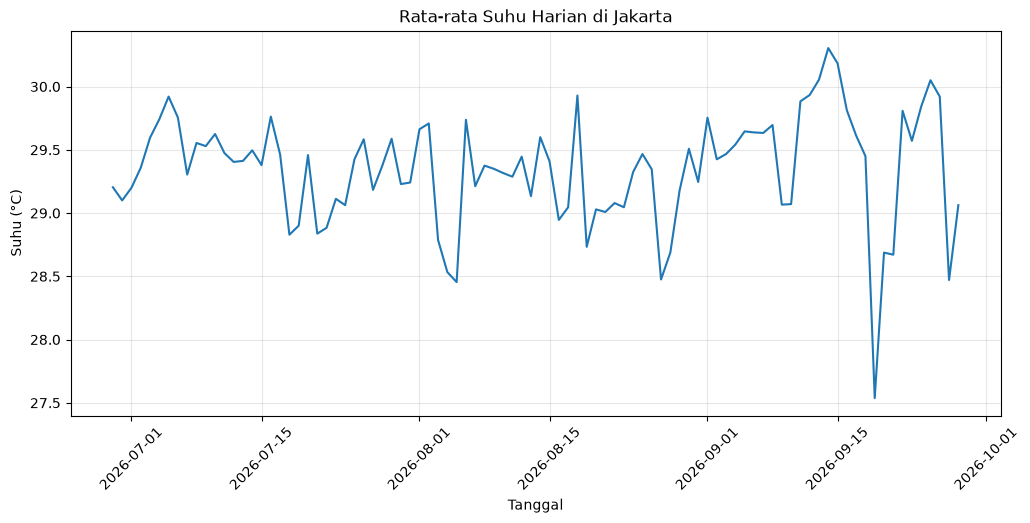

In [21]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_weather.index,
    daily_weather["temperature_2m"]
)

plt.title("Rata-rata Suhu Harian di Jakarta")
plt.xlabel("Tanggal")
plt.ylabel("Suhu (°C)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

##Visualisasi curah hujan harian lebih tepat memakai total

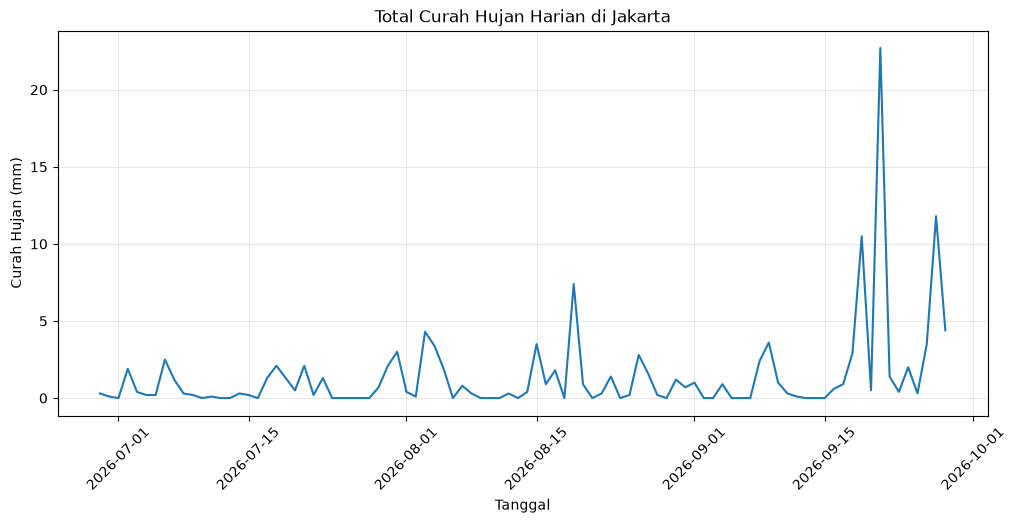

In [22]:
daily_rain = (
    df_final
    .set_index("time")["precipitation"]
    .resample("D")
    .sum()
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_rain.index,
    daily_rain.values
)

plt.title("Total Curah Hujan Harian di Jakarta")
plt.xlabel("Tanggal")
plt.ylabel("Curah Hujan (mm)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

### Pertanyaan Bisnis 2

**Bagaimana hubungan antara kondisi cuaca dengan kualitas udara di Jakarta, khususnya terhadap konsentrasi PM2.5, PM10, nitrogen dioksida, dan ozon?**

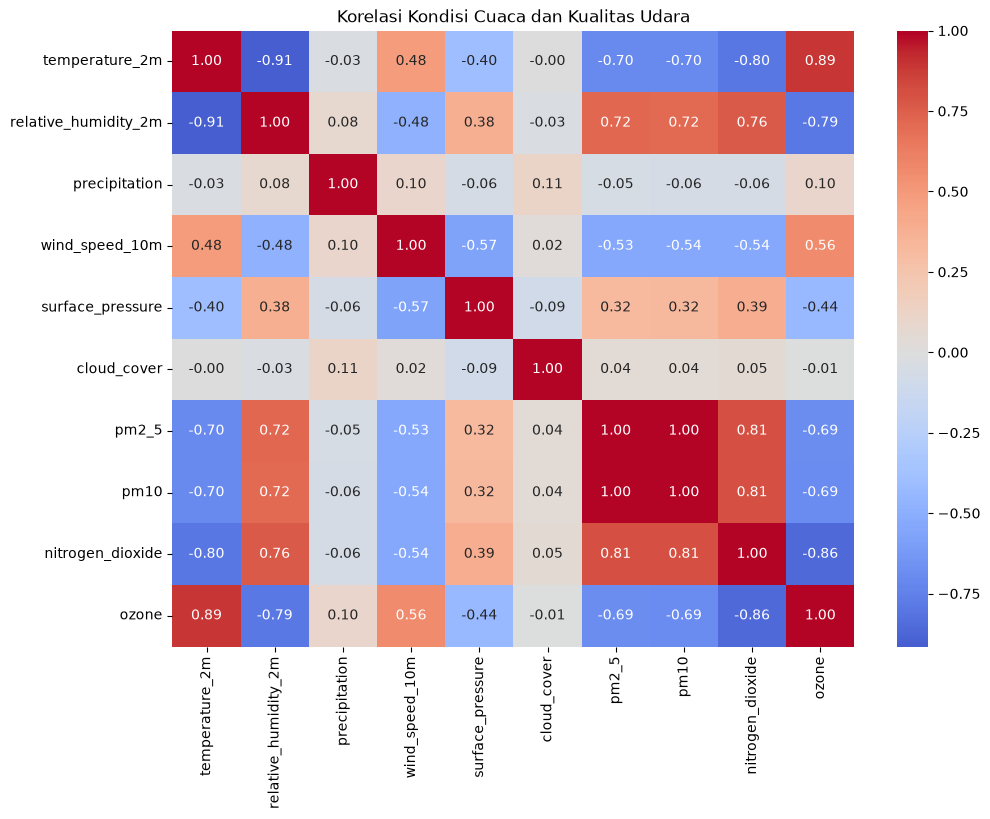

In [23]:
weather_air_cols = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "surface_pressure",
    "cloud_cover",
    "pm2_5",
    "pm10",
    "nitrogen_dioxide",
    "ozone"
]

corr_weather_air = (
    df_final[weather_air_cols]
    .corr()
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_weather_air,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Korelasi Kondisi Cuaca dan Kualitas Udara"
)

plt.show()

In [24]:
air_cols = [
    "pm2_5",
    "pm10",
    "nitrogen_dioxide",
    "ozone"
]

weather_cols_analysis = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "surface_pressure",
    "cloud_cover"
]

correlation_weather_air = (
    df_final[
        weather_cols_analysis + air_cols
    ]
    .corr()
    .loc[
        weather_cols_analysis,
        air_cols
    ]
)

correlation_weather_air

,pm2_5,pm10,nitrogen_dioxide,ozone
temperature_2m,-0.699378,-0.699235,-0.798215,0.894170
relative_humidity_2m,0.719884,0.715500,0.762701,-0.789204
precipitation,-0.053518,-0.056558,-0.060932,0.096920
wind_speed_10m,-0.534173,-0.539762,-0.538201,0.559626
surface_pressure,0.315246,0.323786,0.389992,-0.435969
cloud_cover,0.043488,0.044153,0.053253,-0.009742


### Pertanyaan Bisnis 3

**Bagaimana hubungan suhu permukaan laut dengan kondisi cuaca di Jakarta, terutama suhu udara, kelembapan, tutupan awan, dan curah hujan?**

In [25]:
marine_weather_cols = [
    "sea_surface_temperature",
    "temperature_2m",
    "relative_humidity_2m",
    "cloud_cover",
    "precipitation"
]

sst_corr = (
    df_final[marine_weather_cols]
    .corr()
)

sst_corr

,sea_surface_temperature,temperature_2m,relative_humidity_2m,cloud_cover,precipitation
sea_surface_temperature,1.000000,0.226039,-0.106607,-0.063458,0.087375
temperature_2m,0.226039,1.000000,-0.914875,-0.000441,-0.027861
relative_humidity_2m,-0.106607,-0.914875,1.000000,-0.030274,0.076030
cloud_cover,-0.063458,-0.000441,-0.030274,1.000000,0.114669
precipitation,0.087375,-0.027861,0.076030,0.114669,1.000000


##Visualisasi

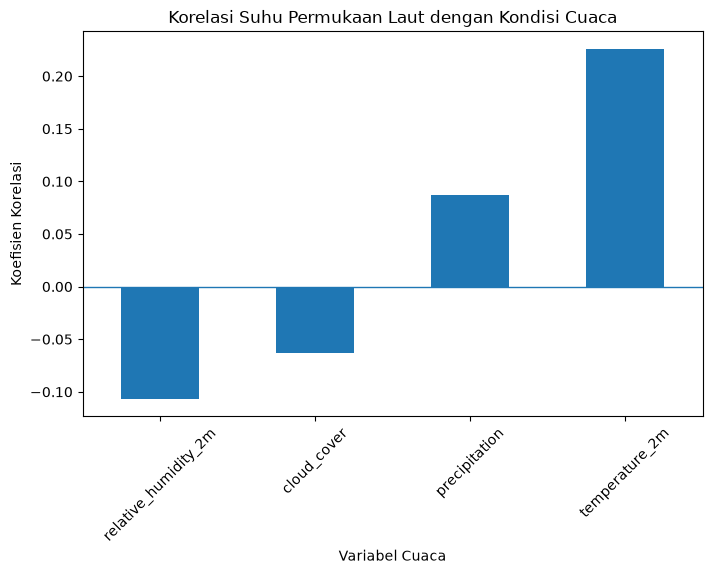

In [26]:
sst_relationship = (
    df_final[marine_weather_cols]
    .corr()["sea_surface_temperature"]
    .drop("sea_surface_temperature")
    .sort_values()
)

plt.figure(figsize=(8, 5))

sst_relationship.plot(
    kind="bar"
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Korelasi Suhu Permukaan Laut dengan Kondisi Cuaca"
)

plt.xlabel("Variabel Cuaca")
plt.ylabel("Koefisien Korelasi")
plt.xticks(rotation=45)
plt.show()

##Scatter antara SST dan suhu udara

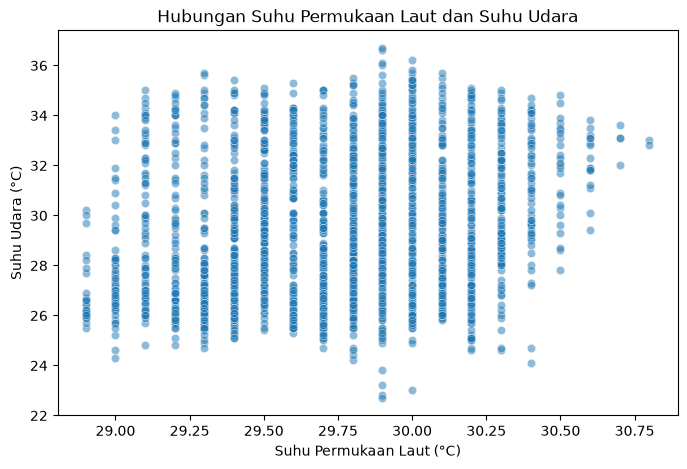

In [27]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_final,
    x="sea_surface_temperature",
    y="temperature_2m",
    alpha=0.5
)

plt.title(
    "Hubungan Suhu Permukaan Laut dan Suhu Udara"
)

plt.xlabel("Suhu Permukaan Laut (°C)")
plt.ylabel("Suhu Udara (°C)")
plt.show()

## 6. Visualisasi & Explanatory Analysis

Visualisasi digunakan untuk memperjelas pola dan hubungan antarvariabel yang ditemukan pada tahap EDA. Interpretasi masing-masing grafik disusun berdasarkan hasil aktual yang diperoleh dari data.

##Distribusi precipitation

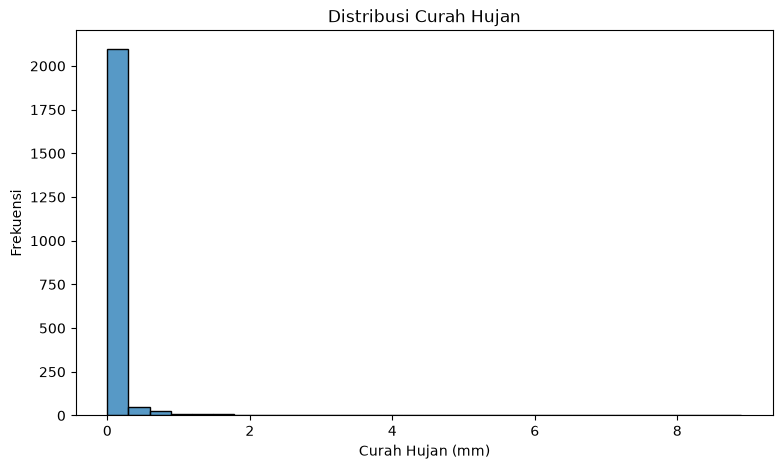

In [28]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df_final["precipitation"],
    bins=30
)

plt.title("Distribusi Curah Hujan")
plt.xlabel("Curah Hujan (mm)")
plt.ylabel("Frekuensi")
plt.show()

## 7. Analisis Lanjutan

Analisis korelasi digunakan sebagai analisis tambahan untuk mengetahui kekuatan hubungan antara variabel cuaca, kualitas udara, dan suhu permukaan laut. Hasil korelasi juga dapat membantu memahami variabel yang memiliki hubungan paling kuat dengan kondisi lingkungan.

## 8. Model AI / Machine Learning

Model klasifikasi digunakan untuk menjawab pertanyaan bisnis keempat, yaitu membandingkan kemampuan Random Forest dan Gradient Boosting dalam memprediksi kondisi hujan atau tidak hujan.

Target klasifikasi dibentuk berdasarkan nilai `precipitation`:

- `0` = Tidak Hujan
- `1` = Hujan

Kondisi hujan didefinisikan sebagai nilai precipitation lebih besar dari 0 mm.

##A. Membuat Target

In [29]:
df_model = df_final.copy()

df_model["rain_status"] = np.where(
    df_model["precipitation"] > 0,
    1,
    0
)

print("Distribusi target:")
display(
    df_model["rain_status"]
    .value_counts()
    .rename(index={
        0: "Tidak Hujan",
        1: "Hujan"
    })
)

print("\nPersentase:")
display(
    (
        df_model["rain_status"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
    .rename(index={
        0: "Tidak Hujan",
        1: "Hujan"
    })
)

Distribusi target:


rain_status
Tidak Hujan    1920
Hujan           288
Name: count, dtype: int64


Persentase:


rain_status
Tidak Hujan    86.96
Hujan          13.04
Name: proportion, dtype: float64

##Visualisasi

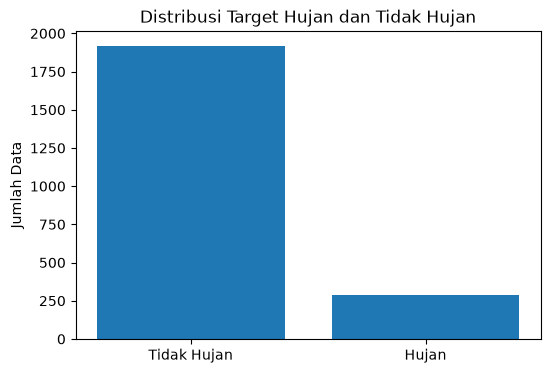

In [30]:
target_counts = (
    df_model["rain_status"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(6, 4))

plt.bar(
    ["Tidak Hujan", "Hujan"],
    target_counts.values
)

plt.title("Distribusi Target Hujan dan Tidak Hujan")
plt.ylabel("Jumlah Data")
plt.show()

##B. Menentukan Feature

In [31]:
feature_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "surface_pressure",
    "cloud_cover",
    "pm2_5",
    "pm10",
    "nitrogen_dioxide",
    "ozone",
    "sea_surface_temperature"
]

X = df_model[feature_columns]
y = df_model["rain_status"]

print("Jumlah feature:", X.shape[1])
print("Jumlah data:", X.shape[0])

Jumlah feature: 10
Jumlah data: 2208


##C. Train-Test Split

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1766, 10)
X_test : (442, 10)
y_train: (1766,)
y_test : (442,)


##D. Random Forest

In [33]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(
    X_train,
    y_train
)

rf_pred = rf_model.predict(
    X_test
)

print("Random Forest selesai dilatih.")

Random Forest selesai dilatih.


##Evaluasi Random Forest

In [34]:
rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    zero_division=0
)

print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1-score :", round(rf_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=[
            "Tidak Hujan",
            "Hujan"
        ],
        zero_division=0
    )
)

Accuracy : 0.862
Precision: 0.4769
Recall   : 0.5345
F1-score : 0.5041

Classification Report:
              precision    recall  f1-score   support

 Tidak Hujan       0.93      0.91      0.92       384
       Hujan       0.48      0.53      0.50        58

    accuracy                           0.86       442
   macro avg       0.70      0.72      0.71       442
weighted avg       0.87      0.86      0.87       442



##Confusion Matrix Random Forest

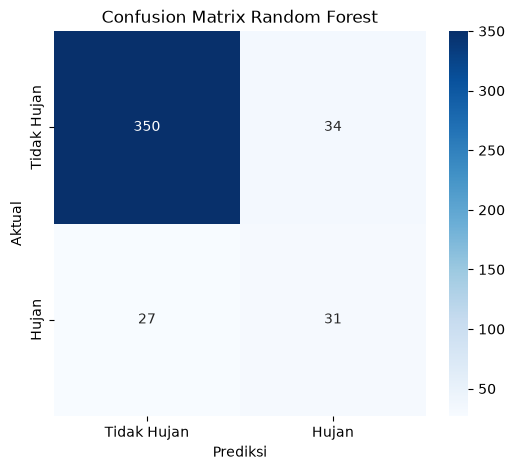

In [35]:
rf_cm = confusion_matrix(
    y_test,
    rf_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Tidak Hujan",
        "Hujan"
    ],
    yticklabels=[
        "Tidak Hujan",
        "Hujan"
    ]
)

plt.title("Confusion Matrix Random Forest")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

##E. Gradient Boosting

In [36]:
gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(
    X_train,
    y_train
)

gb_pred = gb_model.predict(
    X_test
)

print("Gradient Boosting selesai dilatih.")

Gradient Boosting selesai dilatih.


##Evaluasi Gradient Boosting

In [37]:
gb_accuracy = accuracy_score(
    y_test,
    gb_pred
)

gb_precision = precision_score(
    y_test,
    gb_pred,
    zero_division=0
)

gb_recall = recall_score(
    y_test,
    gb_pred,
    zero_division=0
)

gb_f1 = f1_score(
    y_test,
    gb_pred,
    zero_division=0
)

print("Accuracy :", round(gb_accuracy, 4))
print("Precision:", round(gb_precision, 4))
print("Recall   :", round(gb_recall, 4))
print("F1-score :", round(gb_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        gb_pred,
        target_names=[
            "Tidak Hujan",
            "Hujan"
        ],
        zero_division=0
    )
)

Accuracy : 0.8982
Precision: 0.6757
Recall   : 0.431
F1-score : 0.5263

Classification Report:
              precision    recall  f1-score   support

 Tidak Hujan       0.92      0.97      0.94       384
       Hujan       0.68      0.43      0.53        58

    accuracy                           0.90       442
   macro avg       0.80      0.70      0.73       442
weighted avg       0.89      0.90      0.89       442



##Confusion Matrix Gradient Boosting

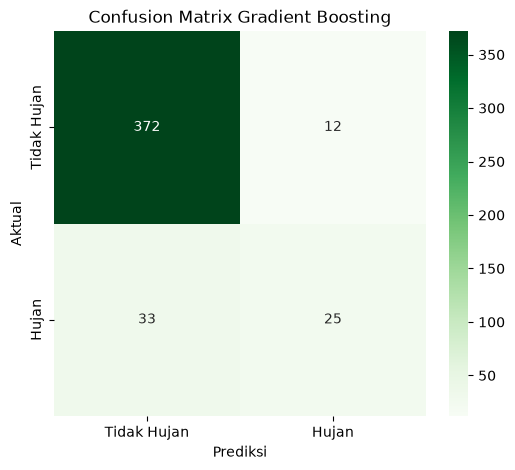

In [38]:
gb_cm = confusion_matrix(
    y_test,
    gb_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    gb_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=[
        "Tidak Hujan",
        "Hujan"
    ],
    yticklabels=[
        "Tidak Hujan",
        "Hujan"
    ]
)

plt.title("Confusion Matrix Gradient Boosting")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

##F. Perbandingan Model

In [39]:
model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        rf_accuracy,
        gb_accuracy
    ],
    "Precision": [
        rf_precision,
        gb_precision
    ],
    "Recall": [
        rf_recall,
        gb_recall
    ],
    "F1-Score": [
        rf_f1,
        gb_f1
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.861991,0.476923,0.534483,0.504065
1,Gradient Boosting,0.898190,0.675676,0.431034,0.526316


##Visualisasi

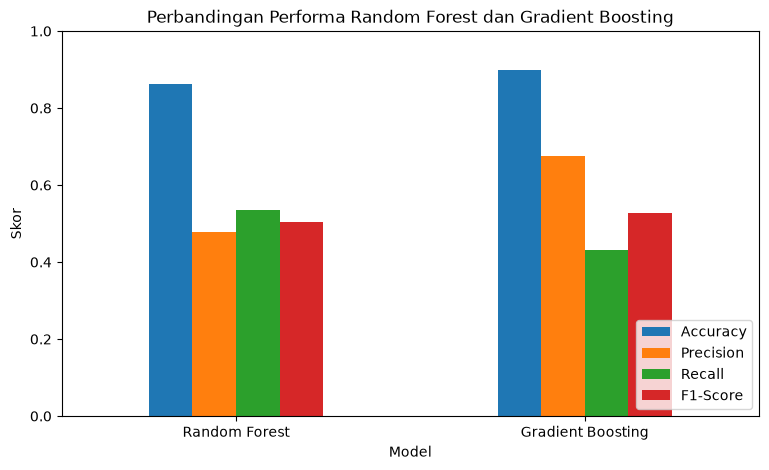

In [40]:
comparison_plot = (
    model_comparison
    .set_index("Model")
)

comparison_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title(
    "Perbandingan Performa Random Forest dan Gradient Boosting"
)

plt.ylabel("Skor")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

##Model Terbaik

In [41]:
best_model_row = (
    model_comparison
    .sort_values(
        "F1-Score",
        ascending=False
    )
    .iloc[0]
)

print(
    "Model terbaik berdasarkan F1-Score:",
    best_model_row["Model"]
)

print(
    "F1-Score:",
    round(
        best_model_row["F1-Score"],
        4
    )
)

Model terbaik berdasarkan F1-Score: Gradient Boosting
F1-Score: 0.5263


##G. Feature Importance (Gradient Boosting)

In [42]:
gb_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": gb_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

gb_importance

,Feature,Importance
8,ozone,0.258892
1,relative_humidity_2m,0.213896
4,cloud_cover,0.165682
7,nitrogen_dioxide,0.083382
9,sea_surface_temperature,0.073615
3,surface_pressure,0.070325
2,wind_speed_10m,0.042795
5,pm2_5,0.038684
0,temperature_2m,0.037411
6,pm10,0.015317


In [44]:
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": gb_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
8,ozone,0.258892
1,relative_humidity_2m,0.213896
4,cloud_cover,0.165682
7,nitrogen_dioxide,0.083382
9,sea_surface_temperature,0.073615
3,surface_pressure,0.070325
2,wind_speed_10m,0.042795
5,pm2_5,0.038684
0,temperature_2m,0.037411
6,pm10,0.015317


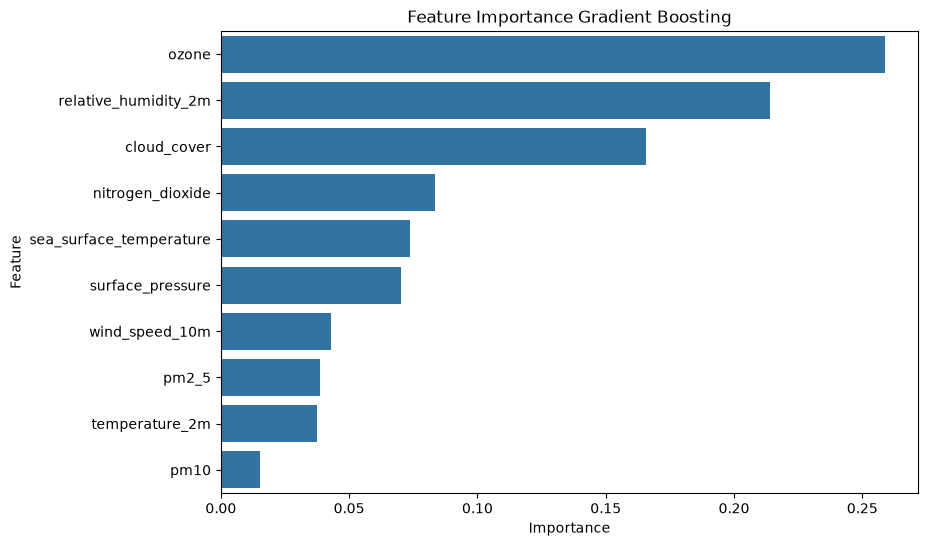

In [45]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

## 9. Conclusion

Kesimpulan disusun berdasarkan hasil EDA, visualisasi, dan evaluasi model untuk menjawab seluruh pertanyaan bisnis.

In [46]:
print("=== RINGKASAN HASIL PROYEK ===")

print("\nPeriode Data:")
print(
    df_final["time"].min(),
    "sampai",
    df_final["time"].max()
)

print("\nJumlah Data Final:")
print(df_final.shape)

print("\nRata-rata Kondisi Cuaca:")
print(
    df_final[
        [
            "temperature_2m",
            "relative_humidity_2m",
            "precipitation",
            "wind_speed_10m",
            "surface_pressure",
            "cloud_cover"
        ]
    ]
    .mean()
    .round(2)
)

print("\nModel Comparison:")
display(
    model_comparison.round(4)
)

print(
    "\nModel terbaik berdasarkan F1-Score:",
    best_model_row["Model"]
)

=== RINGKASAN HASIL PROYEK ===

Periode Data:
2026-06-29 00:00:00 sampai 2026-09-28 23:00:00

Jumlah Data Final:
(2208, 12)

Rata-rata Kondisi Cuaca:
temperature_2m            29.35
relative_humidity_2m      62.61
precipitation              0.06
wind_speed_10m             6.33
surface_pressure        1010.26
cloud_cover               41.18
dtype: float64

Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.8620,0.4769,0.5345,0.5041
1,Gradient Boosting,0.8982,0.6757,0.4310,0.5263



Model terbaik berdasarkan F1-Score: Gradient Boosting
